# MEN 05 — Bottom and side camera agreement

How closely do bottom-camera and side-camera motion energy (ME) follow each other, and does that
change over the session, between task and inter-trial periods, and between licking and not
licking? Every session where both cameras pass the QC (`men_01`) is used.

1. Whole-session correlation: an example, r per session, cross-correlation
2. Across the session: r in 60-s windows against time from the first go cue
3. Task periods and inter-trial periods
4. Lick bouts and the time between them
5. Numbers

The correlation is Pearson r of the two cameras' ME on the 100 Hz grid, over the task span (first
go cue to 10 s after the last). r is computed per session, averaged within animal, and compared
across animals (mean ± SEM, Wilcoxon signed-rank on the paired animal means). Pearson r does not
depend on the per-session normalisation.

## Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import fip_utils as fu
import men_utils as mu
import signal_utils as su
import stats_utils as st
import behavior_utils as bu
import plot_utils as pu
from plotstyle import apply_style, style_ax, save_fig, PALETTE, OKABE_ITO

apply_style()
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="Degrees of freedom <= 0")
pd.set_option("display.width", 200)

In [2]:
IS_CO = os.path.isdir("/root/capsule")

# Same data and cache as men_00
ASSET_CANDIDATES = {
    "3ch": ["/root/capsule/data/DANE_3channels_curated",
            "../../data/results-a278f830-9bf2-48e8-9928-a2ff78e4818f"],
    "4ch": ["/root/capsule/data/DANE_4channels_curated",
            "../../data/results-ddcccb0f-f18f-44a6-a2b1-caba680d28a1"],
}
ME_DATA_ROOT = "/root/capsule/data" if IS_CO else os.environ.get("ME_DATA_ROOT", "../../data")
CACHE_PATH = ("/root/capsule/scratch/men_00/sessions.pkl" if IS_CO
              else os.environ.get("MEN_CACHE", "../../data/men_00_cache/sessions.pkl"))
FIG_DIR = "/root/capsule/scratch/figures/men" if IS_CO else "../data/figures/men"
SAVE_FIG = True

CAMERAS = ("BottomCamera", "SideCameraRight")
BOTTOM, SIDE = CAMERAS
FS = 100.0                # Hz, the men_00 grid
POST_LAST_CUE_S = 10.0    # the task span ends this long after the last go cue
MIN_SAMPLES_S = 30.0      # a period needs this much data (s) in a session for its r

# ── Across the session ───────────────────────────────────────────────────────
ROLL_WIN_S = 60.0
ROLL_STEP_S = 10.0
MIN_SESSIONS_AT_T = 3     # per animal: show a time point only where this many sessions reach it

# ── Periods ──────────────────────────────────────────────────────────────────
TASK_WIN = (0.0, 2.0)     # s after each go cue (cut at the next go cue): cue, choice, outcome
LICK_PAD = (0.2, 0.2)     # a lick bout runs from this long before its first lick to after its last

# ── Cross-correlation ────────────────────────────────────────────────────────
MAXLAG_S = 0.5

# ── Colors ───────────────────────────────────────────────────────────────────
CAM_LABEL = {BOTTOM: "Bottom camera", SIDE: "Side camera"}
CAM_COLOR = {BOTTOM: "0.25", SIDE: OKABE_ITO["sky_blue"]}
C_ALL = PALETTE["all"]
C_TASK, C_ITI = OKABE_ITO["vermillion"], OKABE_ITO["blue"]
C_LICK, C_NOLICK = OKABE_ITO["bluish_green"], OKABE_ITO["reddish_purple"]

## 0. Data

The sessions of `men_00` (its cache), with the same camera screen: a camera the ME table refused
or the image-quality screen excluded has no ME. Only sessions where both cameras are usable are
kept.

In [3]:
asset_roots = {name: root for name, cands in ASSET_CANDIDATES.items()
               if (root := fu.find_asset_root(cands))}
assert asset_roots, "no FIP asset found; check ASSET_CANDIDATES"
me_index = fu.load_me_index(ME_DATA_ROOT)
inv = mu.inventory_sessions(asset_roots, me_index)
inv = inv[inv["path"].notna()]
used = {(r.ses_idx, cam): getattr(r, f"{cam}_status") == "ok" for r in inv.itertuples() for cam in CAMERAS}

all_sessions = mu.load_sessions(inv, fs=FS, cache_path=CACHE_PATH, data_root=ME_DATA_ROOT, cameras=CAMERAS)
sessions = []
for s in all_sessions:
    me = {cam: s["me"][cam] if used[(s["session"], cam)] else None for cam in CAMERAS}
    if any(x is None for x in me.values()):
        continue
    s["me_n"] = {cam: mu.normalise(x, "z") for cam, x in me.items()}
    cues = s["trials"]["goCue_start_time_in_session"].dropna().to_numpy()
    s["span"] = (cues.min(), cues.max() + POST_LAST_CUE_S)
    n = len(s["me_n"][BOTTOM])
    s["in_span"] = su.interval_mask(n, s["t0"], FS, [s["span"][0]], [s["span"][1]])
    sessions.append(s)

SUBJECTS = sorted({s["subject"] for s in sessions})
print(f"{len(all_sessions)} sessions loaded; {len(sessions)} with both cameras usable, "
      f"from {len(SUBJECTS)} animals")
pd.Series([s["subject"] for s in sessions]).value_counts().sort_index().rename("sessions").to_frame().T

loaded 97 sessions from cache ../../data/men_00_cache/sessions.pkl


97 sessions loaded; 62 with both cameras usable, from 8 animals


,800886,808054,809491,815334,816212,816214,818585,818586
sessions,4,15,19,3,5,5,7,4


## 1. Whole-session correlation

**a** One session, 60 s of both cameras (z-scored). **b** r per session over the task span,
by mouse. **c** Cross-correlation, bottom vs side (`su.norm_xcorr(bottom, side)`; a peak at a
positive lag would mean the bottom camera follows the side camera), mean ± SEM across animals.
Both cameras are timed from their own trigger logs on the Harp clock, so the peak should sit at 0.

In [4]:
def masked_r(a, b, mask):
    ok = mask & np.isfinite(a) & np.isfinite(b)
    if ok.sum() < MIN_SAMPLES_S * FS:
        return np.nan
    return np.corrcoef(a[ok], b[ok])[0, 1]


rows, xc = [], []
for s in sessions:
    a, b = s["me_n"][BOTTOM], s["me_n"][SIDE]
    m = s["in_span"]
    lags, c = su.norm_xcorr(np.where(m, a, np.nan), np.where(m, b, np.nan), FS, MAXLAG_S)
    xc.append((s["subject"], c))
    rows.append(dict(subject=s["subject"], session=s["session"], r_session=masked_r(a, b, m),
                     xcorr_peak_lag_s=lags[np.nanargmax(c)],
                     minutes=(s["span"][1] - s["span"][0]) / 60))
per_session = pd.DataFrame(rows)
_, xc_anim = st.group_means([c for _, c in xc], [g for g, _ in xc])
print(per_session[["r_session", "xcorr_peak_lag_s"]].describe().round(3))

       r_session  xcorr_peak_lag_s
count     62.000              62.0
mean       0.893               0.0
std        0.054               0.0
min        0.627               0.0
25%        0.877               0.0
50%        0.907               0.0
75%        0.925               0.0
max        0.950               0.0


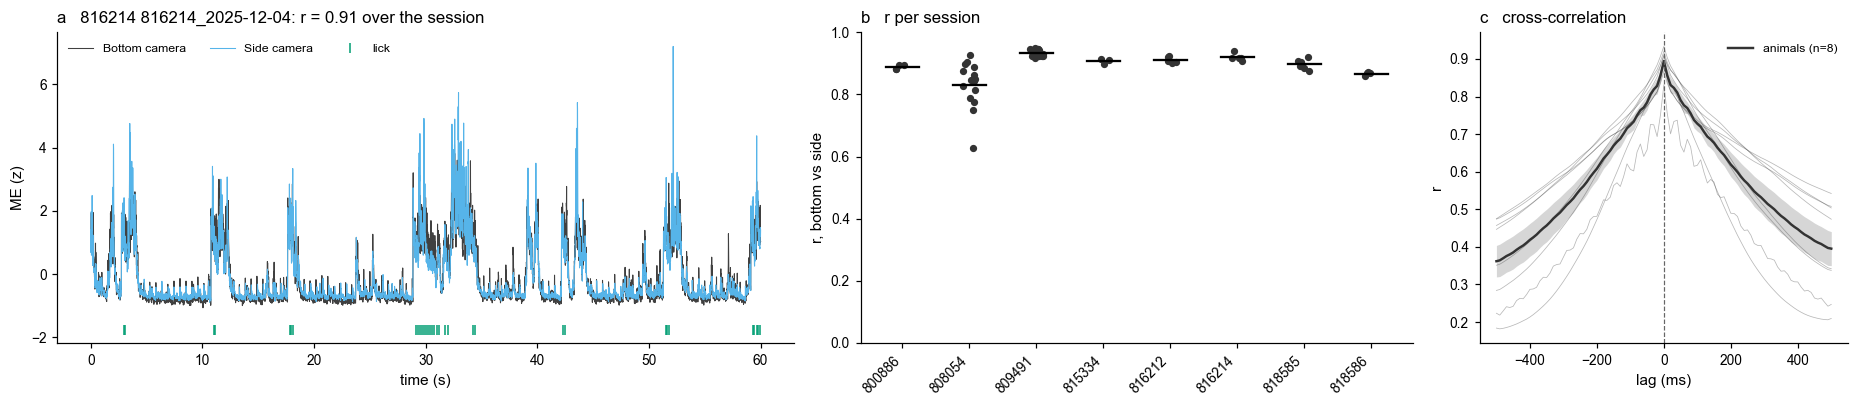

In [5]:
EXAMPLE_WIN_S = 60.0
ex = sessions[int(np.argsort(per_session["r_session"].to_numpy())[len(sessions) // 2])]  # median-r session
t = ex["t0"] + np.arange(len(ex["me_n"][BOTTOM])) / FS
w0 = ex["span"][0] + 0.25 * (ex["span"][1] - ex["span"][0])
win = (t >= w0) & (t < w0 + EXAMPLE_WIN_S)

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1.2, 0.8]))
ax = axes[0]
for cam in CAMERAS:
    ax.plot(t[win] - w0, ex["me_n"][cam][win], color=CAM_COLOR[cam], lw=0.7, label=CAM_LABEL[cam])
licks = ex["licks"][(ex["licks"] >= w0) & (ex["licks"] < w0 + EXAMPLE_WIN_S)] - w0
y_lick = ax.get_ylim()[0] - 0.3
ax.plot(licks, np.full(len(licks), y_lick), "|", color=C_LICK, ms=6, label="lick")
ax.set_ylim(y_lick - 0.4, None)
r_ex = per_session.loc[per_session.session == ex["session"], "r_session"].item()
ax.set(xlabel="time (s)", ylabel="ME (z)")
ax.set_title(f"a   {ex['subject']} {ex['session']}: r = {r_ex:.2f} over the session", loc="left")
ax.legend(fontsize=8, ncol=3, loc="upper left")
style_ax(ax)

ax = axes[1]
rng = np.random.default_rng(0)
for k, subj in enumerate(SUBJECTS):
    v = per_session.loc[per_session.subject == subj, "r_session"]
    ax.scatter(k + (rng.random(len(v)) - 0.5) * 0.2, v, s=14, color=C_ALL)
    ax.plot([k - 0.25, k + 0.25], [v.mean()] * 2, color="k", lw=1.5)
ax.set_xticks(range(len(SUBJECTS)), SUBJECTS, rotation=45, ha="right")
ax.set(ylabel="r, bottom vs side", ylim=(0, 1))
ax.set_title("b   r per session", loc="left")
style_ax(ax)

ax = axes[2]
pu.plot_mean_sem(ax, lags * 1000, xc_anim, C_ALL, "animals", show_rows=True, label_n=True)
ax.axvline(0, color=PALETTE["neutral"], ls="--", lw=0.8)
ax.set(xlabel="lag (ms)", ylabel="r")
ax.set_title("c   cross-correlation", loc="left")
ax.legend(fontsize=8)
style_ax(ax)
fig.tight_layout()
save_fig(fig, "men05_1_whole_session", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 2. Across the session

r in `ROLL_WIN_S`-s windows every `ROLL_STEP_S` s (`su.rolling_corr`), against minutes from the
first go cue, with lick rate over the same windows. Sessions are averaged within animal where at
least `MIN_SESSIONS_AT_T` of that animal's sessions reach that time, and animals where at least
half contribute (`mu.per_animal_timecourse`, as in `men_00` §6).

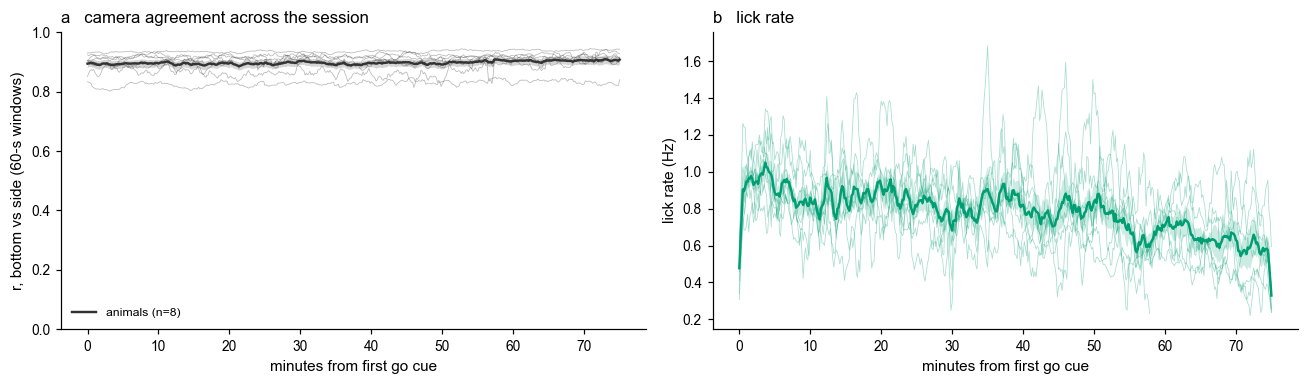

within-session correlation of windowed r with lick rate: -0.49 ± 0.06 across animals (p=0.00781, n=8)


In [6]:
T_GRID = np.arange(0, 120 * 60, ROLL_STEP_S)  # s from the first go cue
roll_r, lick_rate = [], []
for s in sessions:
    a, b = (np.where(s["in_span"], s["me_n"][cam], np.nan) for cam in CAMERAS)
    t_off, r = su.rolling_corr(a, b, FS, ROLL_WIN_S, ROLL_STEP_S)
    roll_r.append((s["subject"], s["t0"] + t_off - s["span"][0], r))
    tc = np.arange(0, s["span"][1] - s["span"][0], ROLL_STEP_S)
    lr = np.array([np.sum(np.abs(s["licks"] - s["span"][0] - tt) < ROLL_WIN_S / 2) for tt in tc]) / ROLL_WIN_S
    lick_rate.append((s["subject"], tc, lr))
r_time = mu.per_animal_timecourse(roll_r, T_GRID, MIN_SESSIONS_AT_T)
lick_time = mu.per_animal_timecourse(lick_rate, T_GRID, MIN_SESSIONS_AT_T)

# per session: r against lick rate across that session's windows
r_vs_lick = []
for (subj, t_r, r), (_, t_l, lr) in zip(roll_r, lick_rate):
    rr = np.interp(t_l, t_r, r, left=np.nan, right=np.nan)
    ok = np.isfinite(rr)
    r_vs_lick.append(dict(subject=subj, r=np.corrcoef(rr[ok], lr[ok])[0, 1] if ok.sum() > 10 else np.nan))
r_vs_lick = pd.DataFrame(r_vs_lick).groupby("subject")["r"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
pu.plot_mean_sem(ax, T_GRID / 60, r_time, C_ALL, "animals", show_rows=True, label_n=True)
ax.set(xlabel="minutes from first go cue", ylabel=f"r, bottom vs side ({ROLL_WIN_S:.0f}-s windows)",
       ylim=(0, 1))
ax.set_title("a   camera agreement across the session", loc="left")
ax.legend(fontsize=8)
style_ax(ax)
ax = axes[1]
pu.plot_mean_sem(ax, T_GRID / 60, lick_time, C_LICK, "animals", show_rows=True, label_n=True)
ax.set(xlabel="minutes from first go cue", ylabel="lick rate (Hz)")
ax.set_title("b   lick rate", loc="left")
style_ax(ax)
fig.tight_layout()
save_fig(fig, "men05_2_across_session", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()
m, p, n = st.wilcoxon_animals(r_vs_lick)
print(f"within-session correlation of windowed r with lick rate: {m:+.2f} ± {r_vs_lick.sem():.2f} "
      f"across animals (p={p:.3g}, n={n})")

## 3. Task periods and inter-trial periods

A **task period** is `TASK_WIN` after each go cue, cut at the next go cue: the cue, the choice and
the start of the outcome. The rest of the task span is **inter-trial**. r is computed separately
over each set of samples. The inter-trial periods include uninstructed licking, which §4 takes
on.

**c** Mean ME in each period. **d** SD of ME around that period's own mean: how much ME varies
*within* the period, not how much movement there is. ME is z-scored over the whole session, so the
SD of any subset is below 1 unless it spans both still and moving stretches (as task periods do).

In [7]:
def paired_panel(ax, df, cols, labels, colors, title):
    for _, r in df.iterrows():
        ax.plot([0, 1], r[cols].to_numpy(float), color="0.8", lw=0.8, zorder=1)
    for i, (col, c) in enumerate(zip(cols, colors)):
        ax.scatter(np.full(len(df), i), df[col], color=c, s=22, zorder=2)
        ax.errorbar(i + (0.18 if i else -0.18), df[col].mean(), df[col].sem(), color="k",
                    marker="o", ms=4, capsize=2)
    d = df[cols[0]] - df[cols[1]]
    m, p, n = st.wilcoxon_animals(d)
    ax.set_xticks([0, 1], labels)
    ax.set_xlim(-0.5, 1.5)
    ax.set(ylabel="r, bottom vs side")
    ax.set_title(f"{title}\nΔr = {m:+.2f}, p = {p:.2g}, n = {n}", loc="left")
    style_ax(ax)


period_rows = []
for s in sessions:
    a, b = s["me_n"][BOTTOM], s["me_n"][SIDE]
    n = len(a)
    tr = s["trials"]
    cue = tr["goCue_start_time_in_session"].to_numpy(float)
    nxt = tr["goCue_start_time_in_session"].shift(-1).fillna(np.inf).to_numpy(float)
    task = su.interval_mask(n, s["t0"], FS, cue + TASK_WIN[0], np.minimum(cue + TASK_WIN[1], nxt)) & s["in_span"]
    bouts = bu.lick_bouts(s["lick_events"])
    lick = su.interval_mask(n, s["t0"], FS, bouts["onset"] - LICK_PAD[0], bouts["offset"] + LICK_PAD[1]) & s["in_span"]
    s["masks"] = dict(task=task, iti=s["in_span"] & ~task, lick=lick, nolick=s["in_span"] & ~lick)
    row = dict(subject=s["subject"], session=s["session"])
    for name, m in s["masks"].items():
        row[f"r_{name}"] = masked_r(a, b, m)
        row[f"frac_{name}"] = m.sum() / s["in_span"].sum()
        # ME level and spread around the period's own mean, in z units of the whole session
        row[f"mean_bottom_{name}"], row[f"mean_side_{name}"] = np.nanmean(a[m]), np.nanmean(b[m])
        row[f"sd_bottom_{name}"], row[f"sd_side_{name}"] = np.nanstd(a[m]), np.nanstd(b[m])
    period_rows.append(row)
periods = pd.DataFrame(period_rows)
period_anim = periods.drop(columns="session").groupby("subject").mean()
period_anim[["frac_task", "frac_iti", "frac_lick", "frac_nolick"]].describe().loc[["mean", "min", "max"]].round(2)

,frac_task,frac_iti,frac_lick,frac_nolick
mean,0.23,0.77,0.18,0.82
min,0.21,0.76,0.16,0.78
max,0.24,0.79,0.22,0.84


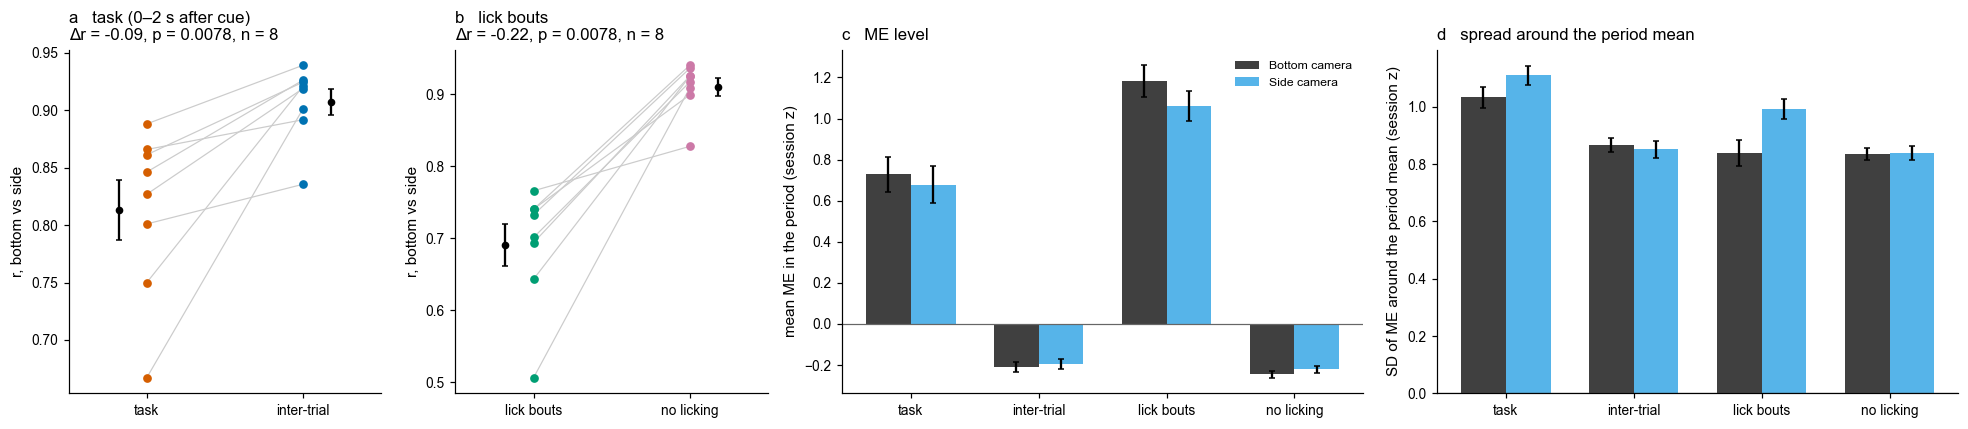

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), gridspec_kw=dict(width_ratios=[0.6, 0.6, 1, 1]))
paired_panel(axes[0], period_anim, ["r_task", "r_iti"], ["task", "inter-trial"], [C_TASK, C_ITI],
             f"a   task ({TASK_WIN[0]:g}–{TASK_WIN[1]:g} s after cue)")
paired_panel(axes[1], period_anim, ["r_lick", "r_nolick"], ["lick bouts", "no licking"],
             [C_LICK, C_NOLICK], "b   lick bouts")

# c, d: ME level in each period, and its spread around that period's mean, both cameras
names = ["task", "iti", "lick", "nolick"]
labels = ["task", "inter-trial", "lick bouts", "no licking"]
w = 0.35
for ax, stat, ylabel, title in (
        (axes[2], "mean", "mean ME in the period (session z)", "c   ME level"),
        (axes[3], "sd", "SD of ME around the period mean (session z)", "d   spread around the period mean")):
    for j, cam in enumerate(("bottom", "side")):
        cols = [f"{stat}_{cam}_{nm}" for nm in names]
        ax.bar(np.arange(4) + (j - 0.5) * w, period_anim[cols].mean(), w, yerr=period_anim[cols].sem(),
               color=CAM_COLOR[CAMERAS[j]], label=CAM_LABEL[CAMERAS[j]], capsize=2)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8)
    ax.set_xticks(range(4), labels)
    ax.set(ylabel=ylabel)
    ax.set_title(title, loc="left")
    style_ax(ax)
axes[2].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "men05_3_periods", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 4. Lick bouts and the time between them

Licks from both spouts are grouped into bouts by the library's `annotate_lick_bouts` (a gap over
0.7 s starts a new bout; `bu.lick_bouts`). A lick-bout period runs from `LICK_PAD[0]` s before the
first lick to `LICK_PAD[1]` s after the last; the rest of the task span is **no licking**. Panel
**b** above compares r in the two; here r in each is shown per session, by mouse, against the
fraction of the session spent licking.

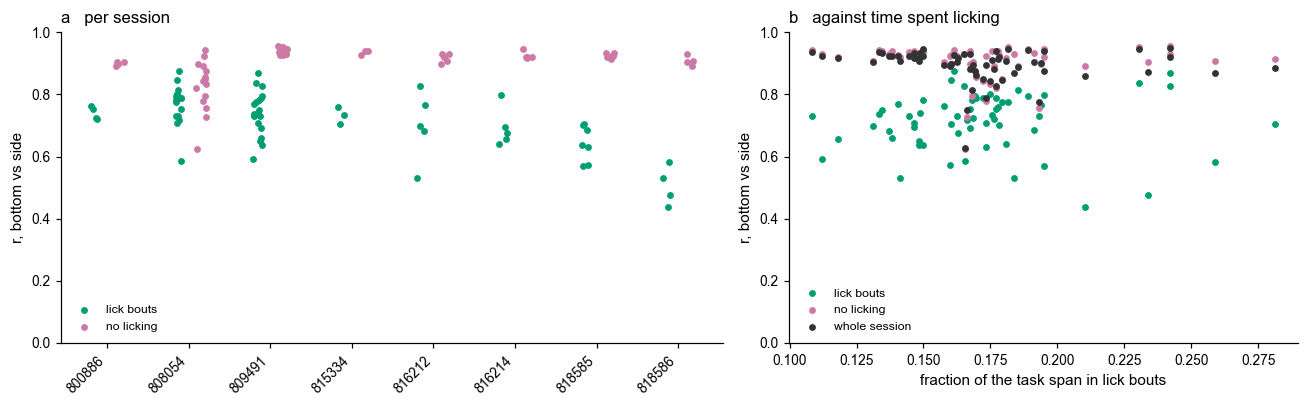

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axes[0]
for k, subj in enumerate(SUBJECTS):
    d = periods[periods.subject == subj]
    for j, (col, c) in enumerate((("r_lick", C_LICK), ("r_nolick", C_NOLICK))):
        ax.scatter(k + (j - 0.5) * 0.3 + (rng.random(len(d)) - 0.5) * 0.12, d[col], s=12, color=c,
                   label=("lick bouts", "no licking")[j] if k == 0 else None)
ax.set_xticks(range(len(SUBJECTS)), SUBJECTS, rotation=45, ha="right")
ax.set(ylabel="r, bottom vs side", ylim=(0, 1))
ax.set_title("a   per session", loc="left")
ax.legend(fontsize=8)
style_ax(ax)

ax = axes[1]
for col, c, lab in (("r_lick", C_LICK, "lick bouts"), ("r_nolick", C_NOLICK, "no licking"),
                    ("r_session", C_ALL, "whole session")):
    v = periods.merge(per_session[["session", "r_session"]], on="session")
    ax.scatter(v["frac_lick"], v[col], s=12, color=c, label=lab)
ax.set(xlabel="fraction of the task span in lick bouts", ylabel="r, bottom vs side", ylim=(0, 1))
ax.set_title("b   against time spent licking", loc="left")
ax.legend(fontsize=8)
style_ax(ax)
fig.tight_layout()
save_fig(fig, "men05_4_licking", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 5. Numbers

Mean ± SEM across animals; paired differences with a Wilcoxon signed-rank test across animals.

In [10]:
def describe(v):
    v = pd.Series(v).dropna()
    return f"{v.mean():.3f} ± {v.sem():.3f} (n={len(v)})"


def paired(a, b):
    d = (a - b).dropna()
    m, p, n = st.wilcoxon_animals(d.values)
    return f"{m:+.3f} ± {d.sem():.3f} (p={p:.3g}, n={n})"


sess_anim = per_session.groupby("subject")[["r_session", "xcorr_peak_lag_s"]].mean()
first = np.nanmean(r_time[:, (T_GRID >= 0) & (T_GRID < 10 * 60)], axis=1)
last = np.array([row[np.isfinite(row)][-60:].mean() if np.isfinite(row).sum() else np.nan for row in r_time])
pa = period_anim
summary = pd.DataFrame([
    ("r over the whole task span", describe(sess_anim["r_session"])),
    ("cross-correlation peak lag (s)", describe(sess_anim["xcorr_peak_lag_s"])),
    ("windowed r, first 10 min", describe(first)),
    ("windowed r, each animal's last 10 min", describe(last)),
    ("last 10 min − first 10 min", paired(pd.Series(last), pd.Series(first))),
    ("within-session corr(windowed r, lick rate)", describe(r_vs_lick)),
    ("r, task periods", describe(pa["r_task"])),
    ("r, inter-trial", describe(pa["r_iti"])),
    ("task − inter-trial", paired(pa["r_task"], pa["r_iti"])),
    ("r, lick bouts", describe(pa["r_lick"])),
    ("r, no licking", describe(pa["r_nolick"])),
    ("lick bouts − no licking", paired(pa["r_lick"], pa["r_nolick"])),
    ("fraction of the span in task periods", describe(pa["frac_task"])),
    ("fraction of the span in lick bouts", describe(pa["frac_lick"])),
], columns=["quantity", "mean ± SEM across animals"])
summary

,quantity,mean ± SEM across animals
0,r over the whole task span,0.894 ± 0.012 (n=8)
1,cross-correlation peak lag (s),0.000 ± 0.000 (n=8)
2,"windowed r, first 10 min",0.894 ± 0.013 (n=8)
3,"windowed r, each animal's last 10 min",0.900 ± 0.012 (n=8)
4,last 10 min − first 10 min,"+0.006 ± 0.004 (p=0.195, n=8)"
5,"within-session corr(windowed r, lick rate)",-0.494 ± 0.055 (n=8)
6,"r, task periods",0.813 ± 0.026 (n=8)
7,"r, inter-trial",0.907 ± 0.012 (n=8)
8,task − inter-trial,"-0.094 ± 0.026 (p=0.00781, n=8)"
9,"r, lick bouts",0.690 ± 0.029 (n=8)
